# Student homework
Complete the blank code cells and write your interpretation under each exercise. Submit a fully executed notebook, including your state choice, convergence evidence, and limitations.


# 2D Prinz: an eight-well Markov state model
Four wells along $x$ and a double well along $y$ give eight physical basins.

$$V(x,y)=2x^8+0.8e^{-80x^2}+0.2e^{-80(x-0.5)^2}+0.5e^{-40(x+0.5)^2}+0.6[(y/0.55)^2-1]^2.$$

$$\mu(x,y)=Z^{-1}e^{-\beta V(x,y)},\qquad \beta=5,\quad (x,y)\in[-1,1]^2.$$

**Numerical model:** a reversible Metropolis-chain discretization on a 40 × 40 lattice. One MC step selects one coordinate, attempts a local move, or stays in place. Rejected moves count as elapsed steps. Time is in **MC steps**, not physical time.

Run the supplied setup and simulation first. No external files or optional packages are required in Google Colab.

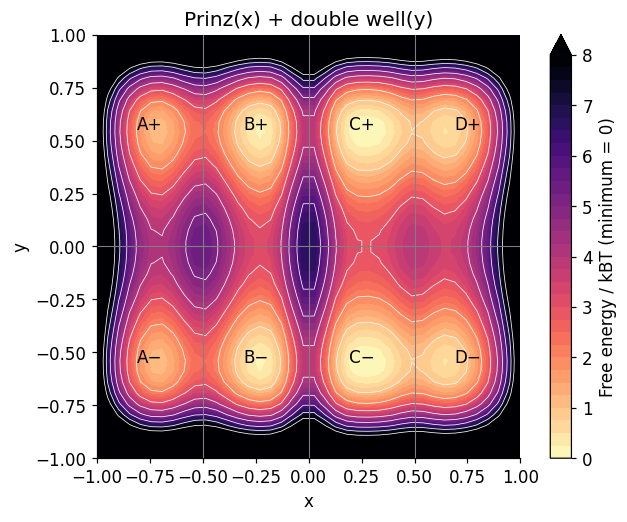

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eigh
from scipy.ndimage import gaussian_filter

plt.rcParams.update({'figure.dpi': 110, 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
SEED = 531
BETA = 5.0
GRID = 40
grid = np.linspace(-1, 1, GRID)
XX, YY = np.meshgrid(grid, grid)

def potential(x, y):
    return (2*x**8 + .8*np.exp(-80*x*x)
            + .2*np.exp(-80*(x-.5)**2) + .5*np.exp(-40*(x+.5)**2)
            + .6*((y/.55)**2-1)**2)

energy = potential(XX, YY)
mu = np.exp(-BETA*(energy-energy.min()))
mu /= mu.sum()  # Probability mass on the lattice, not density per unit area.
fes = BETA*(energy-energy.min())
levels = np.linspace(0, 8, 33)
fig, ax = plt.subplots(figsize=(7, 5))
im = ax.contourf(XX, YY, fes, levels=levels, cmap='magma_r', extend='max')
ax.contour(XX, YY, fes, levels=np.arange(1, 9), colors='white', linewidths=.5)
for boundary in [-.5, 0, .5]: ax.axvline(boundary, color='gray', lw=.7)
ax.axhline(0, color='gray', lw=.7)
for row, y in enumerate([-.55, .55]):
    for col, x in enumerate([-.75, -.25, .25, .75]):
        ax.text(x, y, 'ABCD'[col] + ('−' if row == 0 else '+'), ha='center')
ax.set(xlabel='x', ylabel='y', title='Prinz(x) + double well(y)', aspect='equal')
fig.colorbar(im, ax=ax, label='Free energy / kBT (minimum = 0)')
plt.show()

## Supplied MC simulation
The proposal selects an axis with probability 1/2, then proposes −1, +1, or 0 lattice steps with probabilities 1/4, 1/4, and 1/2. Boundary violations are rejected. Metropolis acceptance is $\min[1,\exp(-eta\Delta V)]$.

The initial point is sampled from equilibrium for transition estimation. Later you will propagate a **different ensemble**, with all population in one MSM state. Increase `N_STEPS` if needed; do not discard rejected steps.

In [2]:
N_STEPS = 600_000
rng = np.random.default_rng(SEED)
# path columns are x-index and y-index; energy is indexed [y, x].
flat = rng.choice(GRID*GRID, p=mu.ravel())
iy, ix = divmod(flat, GRID)
path = np.empty((N_STEPS+1, 2), dtype=np.int16)
path[0] = ix, iy
axis = rng.integers(0, 2, N_STEPS)
move = rng.choice([-1, 0, 1], N_STEPS, p=[.25, .5, .25])
uniform = rng.random(N_STEPS)
for t in range(N_STEPS):
    jx = ix + (move[t] if axis[t] == 0 else 0)
    jy = iy + (move[t] if axis[t] == 1 else 0)
    if 0 <= jx < GRID and 0 <= jy < GRID:
        delta = energy[jy, jx] - energy[iy, ix]
        if uniform[t] < np.exp(min(0., -BETA*delta)):
            ix, iy = jx, jy
    path[t+1] = ix, iy
trajectory = grid[path]
assert np.max(np.abs(np.diff(path.astype(int), axis=0)).sum(axis=1)) <= 1
print(f'{N_STEPS:,} MC steps; trajectory shape = {trajectory.shape}')

600,000 MC steps; trajectory shape = (600001, 2)


## 1. Estimate equilibrium populations and free energy
Estimate the 2D probability distribution from the trajectory, convert it to a free-energy surface, and compare it with the supplied equilibrium distribution. Report the eight basin populations and explain discrepancies. Distinguish probability mass from probability density; do not assign a finite free energy to an unvisited bin without explaining your convention.

In [3]:
# Your implementation here

**Interpretation:** *Your explanation here.*

## 2. Define and visualize MSM states
Choose a partition of the 2D domain, assign every snapshot to a state, and plot the state boundaries and occupancy. Explain your choice. Keep the eight physical basins distinct from the states used to estimate the MSM. Document unvisited states and how you handle them.

In [4]:
# Your implementation here

**Interpretation:** *Your explanation here.*

## 3. Estimate transition probabilities
Count transitions at lag $\tau=100$ MC steps and estimate a reversible transition matrix. Plot it and check nonnegativity, row normalization, connectivity, stationarity, and detailed balance. Explain what each matrix entry means. How does a binned conditional transition probability differ from a continuous transition density?

In [5]:
# Your implementation here

**Interpretation:** *Your explanation here.*

## 4. Compute and visualize the dominant eigenmodes
Solve $T\psi_i=\lambda_i\psi_i$. Normalize the eigenvectors in the equilibrium-weighted inner product and plot the stationary mode and the leading nonstationary modes in the 2D state space. Interpret the population exchanges. Verify the eigenvalue equations and orthogonality. Explain why mode signs do not specify a unique direction of flow.

In [6]:
# Your implementation here

**Interpretation:** *Your explanation here.*

## 5. Chapman–Kolmogorov tests at 100 and 10 MC steps
Compare predictions $[T(\tau)^k]_{ab}$ with transition probabilities estimated directly at $k\tau$, for both $\tau=100$ and $\tau=10$. Include return and interbasin transitions. Plot against elapsed MC steps. Assess sampling uncertainty and revise sampling/partitioning as needed to obtain a convincing test at 100 steps. Report what happens at 10 steps; agreement is not assumed. Do not construct the direct reference by powering the fitted matrix.

In [7]:
# Your implementation here

**Interpretation:** *Your explanation here.*

## 6. Propagate an out-of-equilibrium population
Put all probability in one visited MSM state. Propagate the population with the 100-step model. Plot the population and relative population $u_k=p_k/\pi$ at several times, and compare the long-time result with equilibrium. Check normalization and nonnegativity. Distinguish this evolving ensemble from the cumulative histogram of one MC trajectory.

In [8]:
# Your implementation here

**Interpretation:** *Your explanation here.*

## 7. Calculate amplitudes and reconstruct mode decay
Calculate $a_i=\sum_s p_{0,s}\psi_i(s)$ and reconstruct $p_{k,s}=\pi_s\sum_i a_i\lambda_i^k\psi_i(s)$. Verify agreement with direct matrix propagation. Plot the signed amplitudes and spatial mode contributions at several lags. Compare a reconstruction using a few dominant modes with the complete reconstruction.

In [9]:
# Your implementation here

**Interpretation:** *Your explanation here.*

## 8. Autocorrelations and relaxation times
Evaluate each leading nonstationary eigenvector along the sampled state trajectory. Compute its normalized autocorrelation and compare it with $\lambda_i^k$. Calculate $t_i=-\tau/\ln\lambda_i$ for positive eigenvalues below one. Compare implied timescales at multiple model lags and explain statistical and discretization limitations. Do not assign a finite relaxation time to the stationary mode.

In [10]:
# Your implementation here

**Interpretation:** *Your explanation here.*